# Retail Sales Forecasting — Data Exploration

This first notebook loads the Kaggle **Store Sales - Time Series Forecasting** data and inspects dataset dimensions, column types, date ranges, missing values, duplicates, sales distributions, and the first rows.

It does **not** train a model. If the dataset is missing from `data/raw/`, the notebook explains how to download it and skips the data-dependent cells instead of inventing data.

## 1. Set up imports and paths

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from retail_sales_forecasting.config import FIGURES_DIR, RAW_DATA_DIR
from retail_sales_forecasting.data_loader import (
    available_datasets,
    load_available_datasets,
    missing_datasets,
)
from retail_sales_forecasting.validation import (
    format_validation_report,
    validate_dataset,
)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {RAW_DATA_DIR}")

Project root: D:\code\retail-sales-forecasting-main
Raw data directory: D:\code\retail-sales-forecasting-main\data\raw


## 2. Check the raw dataset files

Download the competition files from <https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data> and place the CSVs directly in `data/raw/`.

Required files: `train.csv`, `test.csv`, `stores.csv`, `oil.csv`, `holidays_events.csv`, and `transactions.csv`.

In [2]:
available = available_datasets()
missing = missing_datasets()

print("Available:", ", ".join(available) if available else "none")
print("Missing:", ", ".join(missing) if missing else "none")

Available: train, test, stores, oil, holidays_events, transactions
Missing: none


## 3. Load the available data

The loader parses each dataset's `date` column automatically. If `train.csv` is missing, the cells below print a reminder instead of creating sample data.

In [3]:
if "train" in available:
    datasets = load_available_datasets()
    train = datasets["train"]
    print(f"Loaded {len(datasets)} datasets.")
    print(f"train.csv: {train.shape[0]:,} rows x {train.shape[1]:,} columns")
else:
    datasets = {}
    train = None
    print(
        "train.csv is not available. Download the competition data from "
        "https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data "
        "and place it in data/raw/, then re-run this notebook."
    )

Loaded 6 datasets.
train.csv: 3,000,888 rows x 6 columns


## 4. Dataset inventory

Shape and date coverage for every available CSV file.

In [4]:
if datasets:
    inventory = []
    for name, frame in datasets.items():
        row = {
            "dataset": name,
            "rows": frame.shape[0],
            "columns": frame.shape[1],
            "date_start": None,
            "date_end": None,
        }
        if "date" in frame.columns:
            row["date_start"] = frame["date"].min().date()
            row["date_end"] = frame["date"].max().date()
        inventory.append(row)

    display(pd.DataFrame(inventory).set_index("dataset"))
else:
    print("Skipped: training data is not loaded.")

,rows,columns,date_start,date_end
dataset,,,,
train,3000888,6,2013-01-01,2017-08-15
test,28512,5,2017-08-16,2017-08-31
stores,54,5,None,None
oil,1218,2,2013-01-01,2017-08-31
holidays_events,350,6,2012-03-02,2017-12-26
transactions,83488,3,2013-01-01,2017-08-15


## 5. Training dataset dimensions

In [5]:
if train is not None:
    print(f"Rows: {train.shape[0]:,}")
    print(f"Columns: {train.shape[1]:,}")
    display(train.shape)
else:
    print("Skipped: training data is not loaded.")

Rows: 3,000,888
Columns: 6


(3000888, 6)

## 6. Column types

In [6]:
if train is not None:
    display(train.dtypes.to_frame(name="dtype"))
else:
    print("Skipped: training data is not loaded.")

,dtype
id,int64
date,datetime64[ns]
store_nbr,int64
family,object
sales,float64
onpromotion,int64


## 7. Training date range

In [7]:
if train is not None:
    print(f"Start date: {train['date'].min().date()}")
    print(f"End date: {train['date'].max().date()}")
    print(f"Distinct dates: {train['date'].nunique():,}")
else:
    print("Skipped: training data is not loaded.")

Start date: 2013-01-01
End date: 2017-08-15
Distinct dates: 1,684


## 8. Missing values

Missing values are listed for every loaded dataset. For example, `oil.csv` has gaps in the oil price series.

In [8]:
if datasets:
    missing_rows = []
    for name, frame in datasets.items():
        missing_counts = frame.isna().sum()
        for column, count in missing_counts[missing_counts > 0].items():
            missing_rows.append(
                {"dataset": name, "column": column, "missing_count": int(count)}
            )

    if missing_rows:
        display(pd.DataFrame(missing_rows).set_index(["dataset", "column"]))
    else:
        print("No missing values found in the loaded datasets.")
else:
    print("Skipped: training data is not loaded.")

,,missing_count
dataset,column,
oil,dcoilwtico,43


## 9. Duplicate rows and keys

A valid training row should be unique for each `date`, `store_nbr`, and `family` combination.

In [9]:
if train is not None:
    duplicate_rows = int(train.duplicated().sum())
    duplicate_keys = int(
        train.duplicated(["date", "store_nbr", "family"]).sum()
    )
    duplicate_ids = int(train["id"].duplicated().sum())

    print(f"Duplicate full rows: {duplicate_rows:,}")
    print(f"Duplicate date/store/family keys: {duplicate_keys:,}")
    print(f"Duplicate ids: {duplicate_ids:,}")
else:
    print("Skipped: training data is not loaded.")

Duplicate full rows: 0
Duplicate date/store/family keys: 0
Duplicate ids: 0


## 10. Sales distribution

Sales are highly skewed, with many zero-sales rows. The `log1p` transformation is used only for visualization; the underlying data is unchanged.

,sales
count,3.000888e+06
mean,3.577757e+02
std,1.101998e+03
min,0.000000e+00
1%,0.000000e+00
25%,0.000000e+00
50%,1.100000e+01
75%,1.958473e+02
90%,8.670000e+02
99%,5.507000e+03


Zero-sales rows: 939,130 (31.3%)
Negative-sales rows: 0


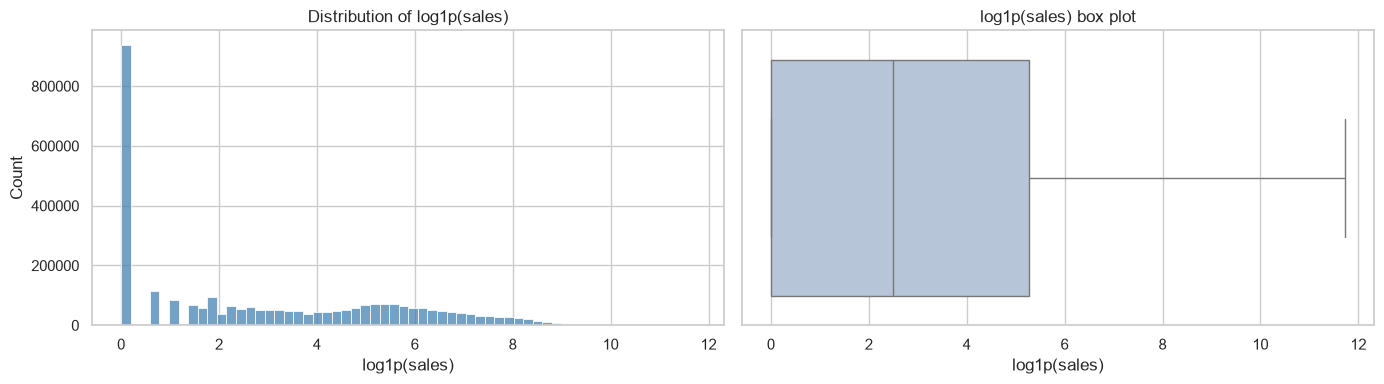

Saved figure: D:\code\retail-sales-forecasting-main\reports\figures\week1_sales_distribution.png


In [10]:
if train is not None:
    sales = train["sales"]
    summary = sales.describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.9, 0.99]
    ).to_frame(name="sales")
    display(summary)

    zero_sales = int((sales == 0).sum())
    negative_sales = int((sales < 0).sum())
    print(f"Zero-sales rows: {zero_sales:,} ({zero_sales / len(sales):.1%})")
    print(f"Negative-sales rows: {negative_sales:,}")

    log_sales = np.log1p(sales)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(log_sales, bins=60, ax=axes[0], color="steelblue")
    axes[0].set_title("Distribution of log1p(sales)")
    axes[0].set_xlabel("log1p(sales)")

    sns.boxplot(x=log_sales, ax=axes[1], color="lightsteelblue")
    axes[1].set_title("log1p(sales) box plot")
    axes[1].set_xlabel("log1p(sales)")

    fig.tight_layout()
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    figure_path = FIGURES_DIR / "week1_sales_distribution.png"
    fig.savefig(figure_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {figure_path}")
else:
    print("Skipped: training data is not loaded.")

## 11. First few rows

In [11]:
if train is not None:
    display(train.head())
else:
    print("Skipped: training data is not loaded.")

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 12. Basic validation

This checks required columns, dimensions, date parsing, and missing values.

In [12]:
if train is not None:
    result = validate_dataset(train, "train")
    print(format_validation_report(result))
else:
    print("Skipped: training data is not loaded.")

Dataset: train (train.csv)
Dimensions: 3,000,888 rows x 6 columns
Required columns: 6/6 present
Missing required columns: none
Unparseable/missing dates: none
Missing values: none
Status: OK


## Next steps

Week 2 explores sales trends, seasonality, and relationships with stores, families, promotions, holidays, transactions, and oil prices. No model is trained in this notebook.